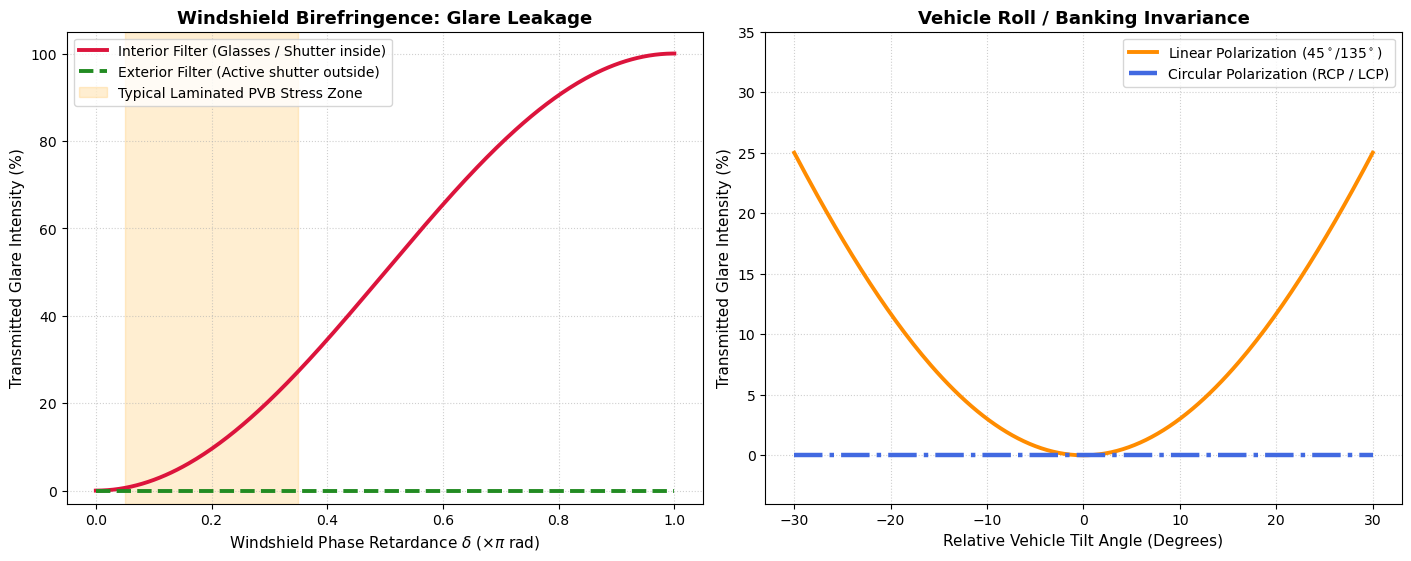

In [1]:
# import numpy as np
# import matplotlib.pyplot as plt

# # ==========================================
# # 1. JONES CALCULUS MATRIX DEFINITIONS
# # ==========================================

# def rotation_matrix(theta_rad):
#     """Coordinate rotation matrix R(theta)."""
#     c, s = np.cos(theta_rad), np.sin(theta_rad)
#     return np.array([[c, s],
#                      [-s, c]], dtype=complex)

# def linear_polarizer(angle_rad):
#     """Linear polarizer oriented at angle_rad."""
#     R = rotation_matrix(angle_rad)
#     R_inv = rotation_matrix(-angle_rad)
#     # Horizontal polarizer at 0 rad
#     lp_0 = np.array([[1, 0],
#                      [0, 0]], dtype=complex)
#     return R_inv @ lp_0 @ R

# def quarter_wave_plate(fast_axis_rad):
#     """Quarter-Wave Plate (pi/2 retardance) at arbitrary fast axis."""
#     R = rotation_matrix(fast_axis_rad)
#     R_inv = rotation_matrix(-fast_axis_rad)
#     # Fast axis horizontal: phase advance of pi/2 on x
#     qwp_0 = np.array([[np.exp(1j * np.pi / 4), 0],
#                       [0, np.exp(-1j * np.pi / 4)]], dtype=complex)
#     return R_inv @ qwp_0 @ R

# def birefringent_medium(retardance_delta, fast_axis_rad=np.pi / 4):
#     """Models stressed glass with phase retardance delta and principal stress axis."""
#     R = rotation_matrix(fast_axis_rad)
#     R_inv = rotation_matrix(-fast_axis_rad)
#     retarder_0 = np.array([[np.exp(1j * retardance_delta / 2), 0],
#                            [0, np.exp(-1j * retardance_delta / 2)]], dtype=complex)
#     return R_inv @ retarder_0 @ R

# def compute_intensity(E_field):
#     """Computes normalized optical intensity I = |Ex|^2 + |Ey|^2."""
#     return np.real(np.vdot(E_field, E_field))


# # ==========================================
# # 2. OPTICAL ELEMENT SPECIFICATIONS
# # ==========================================

# # Incident Right Circularly Polarized (RCP) headlight from oncoming vehicle
# # E_RCP = 1/sqrt(2) * [1, -i]^T
# E_headlight_RCP = (1.0 / np.sqrt(2.0)) * np.array([1.0, -1j], dtype=complex)

# # Circular Polarization (CP) Analyzer to extinguish RCP:
# # QWP fast axis at 0 rad converts RCP back to 45° linear.
# # Followed by a Linear Polarizer at 135° (3*pi/4) to extinguish it.
# J_QWP_analyzer = quarter_wave_plate(0.0)
# J_LP_analyzer  = linear_polarizer(3 * np.pi / 4)
# J_analyzer     = J_LP_analyzer @ J_QWP_analyzer


# # ==========================================
# # 3. EXPERIMENT A: WINDSHIELD RETARDANCE LEAKAGE
# # ==========================================

# # Retardance delta from 0 to pi (stressed PVB / tempered vs laminated)
# delta_vals = np.linspace(0, np.pi, 300)
# leakage_interior = []
# leakage_exterior = []

# for d in delta_vals:
#     J_windshield = birefringent_medium(retardance_delta=d, fast_axis_rad=np.pi / 6)
    
#     # 1. Interior Shutter / Sunglasses (Fails):
#     # Light -> Windshield -> Filter -> Eye
#     E_out_int = J_analyzer @ J_windshield @ E_headlight_RCP
#     leakage_interior.append(compute_intensity(E_out_int))
    
#     # 2. Exterior Shutter (Succeeds):
#     # Light -> Filter -> Windshield -> Eye
#     E_out_ext = J_windshield @ J_analyzer @ E_headlight_RCP
#     leakage_exterior.append(compute_intensity(E_out_ext))

# leakage_interior = np.array(leakage_interior) * 100  # Percentage
# leakage_exterior = np.array(leakage_exterior) * 100


# # ==========================================
# # 4. EXPERIMENT B: BANK ANGLE / ROLL INVARIANCE
# # ==========================================

# # Relative vehicle tilt angle theta from -30° to +30°
# tilt_deg = np.linspace(-30, 30, 200)
# tilt_rad = np.radians(tilt_deg)

# glare_linear = []
# glare_circular = []

# for t in tilt_rad:
#     # Linear Setup: 45° Headlight vs 135° + tilt Glasses
#     # E_linear = [cos(45°), sin(45°)]
#     E_lin = np.array([np.cos(np.pi / 4), np.sin(np.pi / 4)], dtype=complex)
#     J_lin_analyzer = linear_polarizer(3 * np.pi / 4 + t)
#     E_out_lin = J_lin_analyzer @ E_lin
#     glare_linear.append(compute_intensity(E_out_lin))
    
#     # Circular Setup: RCP is invariant to roll rotation
#     # Rotating the analyzer by roll angle t
#     R_t = rotation_matrix(t)
#     R_t_inv = rotation_matrix(-t)
#     J_analyzer_tilted = R_t_inv @ J_analyzer @ R_t
#     E_out_circ = J_analyzer_tilted @ E_headlight_RCP
#     glare_circular.append(compute_intensity(E_out_circ))

# glare_linear = np.array(glare_linear) * 100
# glare_circular = np.array(glare_circular) * 100


# # ==========================================
# # 5. VISUALIZATION & PLOTTING
# # ==========================================

# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# # Plot 1: The Birefringence Leakage
# ax1.plot(delta_vals / np.pi, leakage_interior, color='crimson', lw=2.5, 
#          label='Interior Filter (Glasses / Shutter inside)')
# ax1.plot(delta_vals / np.pi, leakage_exterior, color='forestgreen', lw=2.5, linestyle='--', 
#          label='Exterior Filter (Active shutter outside)')
# ax1.axvspan(0.05, 0.35, color='orange', alpha=0.15, label='Typical Laminated PVB Stress Zone')
# ax1.set_title('Windshield Birefringence: Glare Leakage', fontsize=13, fontweight='bold')
# ax1.set_xlabel(r'Windshield Phase Retardance $\delta$ ($\times \pi$ rad)', fontsize=11)
# ax1.set_ylabel('Transmitted Glare Intensity (%)', fontsize=11)
# ax1.set_ylim(-2, 105)
# ax1.grid(True, linestyle=':', alpha=0.6)
# ax1.legend(loc='upper left', frameon=True)

# # Plot 2: Vehicle Roll Invariance
# ax2.plot(tilt_deg, glare_linear, color='darkorange', lw=2.5, 
#          label=r'Linear Polarization ($45^\circ / 135^\circ$)')
# # ax2.plot(tilt_deg, glare_circular, color='royalblue', lw=2.5, linestyle='--', 
# #          label='Circular Polarization (RCP / LCP)')
# ax2.plot(tilt_deg, glare_circular, color='royalblue', lw=3.5, label='Circular Polarization (RCP / LCP)')
# ax2.set_ylim(-5, 35)  # Drop the floor so 0% sits clearly above the bottom spine
# ax2.set_title('Vehicle Roll / Banking Invariance', fontsize=13, fontweight='bold')
# ax2.set_xlabel('Relative Vehicle Tilt Angle (Degrees)', fontsize=11)
# ax2.set_ylabel('Transmitted Glare Intensity (%)', fontsize=11)
# ax2.set_ylim(-2, 35)
# ax2.grid(True, linestyle=':', alpha=0.6)
# ax2.legend(loc='upper right', frameon=True)

# plt.tight_layout()
# plt.show()
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. JONES CALCULUS MATRIX DEFINITIONS
# ==========================================

def rotation_matrix(theta_rad):
    c, s = np.cos(theta_rad), np.sin(theta_rad)
    return np.array([[c, s],
                     [-s, c]], dtype=complex)

def linear_polarizer(angle_rad):
    R = rotation_matrix(angle_rad)
    R_inv = rotation_matrix(-angle_rad)
    lp_0 = np.array([[1, 0], [0, 0]], dtype=complex)
    return R_inv @ lp_0 @ R

def quarter_wave_plate(fast_axis_rad):
    R = rotation_matrix(fast_axis_rad)
    R_inv = rotation_matrix(-fast_axis_rad)
    # Fast axis horizontal: advance x by pi/2 relative to y
    qwp_0 = np.array([[np.exp(1j * np.pi / 4), 0],
                      [0, np.exp(-1j * np.pi / 4)]], dtype=complex)
    return R_inv @ qwp_0 @ R

def birefringent_medium(retardance_delta, fast_axis_rad=np.pi / 4):
    R = rotation_matrix(fast_axis_rad)
    R_inv = rotation_matrix(-fast_axis_rad)
    retarder_0 = np.array([[np.exp(1j * retardance_delta / 2), 0],
                           [0, np.exp(-1j * retardance_delta / 2)]], dtype=complex)
    return R_inv @ retarder_0 @ R

def compute_intensity(E_field):
    return np.real(np.vdot(E_field, E_field))

# ==========================================
# 2. OPTICAL SYSTEM SETUP (PROPER RCP EXTINCTION)
# ==========================================

# Incident Right Circularly Polarized (RCP) light from oncoming headlights
# E_RCP = 1/sqrt(2) * [1, -i]^T
E_headlight_RCP = (1.0 / np.sqrt(2.0)) * np.array([1.0, -1j], dtype=complex)

# True RCP Extinction Analyzer:
# 1. QWP with fast axis at 0 rad transforms RCP into -45° (135°) linear light
# 2. Linear Polarizer at 45° (orthogonal to 135°) extinguishes it completely
J_QWP_analyzer = quarter_wave_plate(0.0)
J_LP_analyzer  = linear_polarizer(np.pi / 4)
J_analyzer     = J_LP_analyzer @ J_QWP_analyzer

# Verify extinction at zero stress: should be 0.0000
assert compute_intensity(J_analyzer @ E_headlight_RCP) < 1e-10

# ==========================================
# 3. EXPERIMENT A: WINDSHIELD BIREFRINGENCE LEAKAGE
# ==========================================

delta_vals = np.linspace(0, np.pi, 300)
leakage_interior = []
leakage_exterior = []

for d in delta_vals:
    J_windshield = birefringent_medium(retardance_delta=d, fast_axis_rad=np.pi / 6)
    
    # 1. Interior Filter (Light -> Windshield -> Filter -> Eye):
    # Stressed glass distorts RCP -> elliptical, causing glare leakage
    E_out_int = J_analyzer @ J_windshield @ E_headlight_RCP
    leakage_interior.append(compute_intensity(E_out_int))
    
    # 2. Exterior Filter (Light -> Filter -> Windshield -> Eye):
    # Glare is cancelled to 0 BEFORE reaching the glass
    E_out_ext = J_windshield @ J_analyzer @ E_headlight_RCP
    leakage_exterior.append(compute_intensity(E_out_ext))

leakage_interior = np.array(leakage_interior) * 100
leakage_exterior = np.array(leakage_exterior) * 100

# ==========================================
# 4. EXPERIMENT B: BANK ANGLE / ROLL INVARIANCE
# ==========================================

tilt_deg = np.linspace(-30, 30, 200)
tilt_rad = np.radians(tilt_deg)

glare_linear = []
glare_circular = []

for t in tilt_rad:
    # Linear: 45° emission vs 135° + roll analyzer
    E_lin = np.array([np.cos(np.pi / 4), np.sin(np.pi / 4)], dtype=complex)
    J_lin_analyzer = linear_polarizer(3 * np.pi / 4 + t)
    E_out_lin = J_lin_analyzer @ E_lin
    glare_linear.append(compute_intensity(E_out_lin))
    
    # Circular: Analyzer rotated by vehicle roll angle t
    R_t = rotation_matrix(t)
    R_t_inv = rotation_matrix(-t)
    J_analyzer_tilted = R_t_inv @ J_analyzer @ R_t
    E_out_circ = J_analyzer_tilted @ E_headlight_RCP
    glare_circular.append(compute_intensity(E_out_circ))

glare_linear = np.array(glare_linear) * 100
glare_circular = np.array(glare_circular) * 100

# ==========================================
# 5. VISUALIZATION
# ==========================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), layout='constrained')

# Plot 1: Birefringence Leakage (Fixed Directions)
ax1.plot(delta_vals / np.pi, leakage_interior, color='crimson', lw=2.8, 
         label='Interior Filter (Glasses / Shutter inside)')
ax1.plot(delta_vals / np.pi, leakage_exterior, color='forestgreen', lw=2.8, linestyle='--', 
         label='Exterior Filter (Active shutter outside)')
ax1.axvspan(0.05, 0.35, color='orange', alpha=0.18, label='Typical Laminated PVB Stress Zone')
ax1.set_title('Windshield Birefringence: Glare Leakage', fontsize=13, fontweight='bold')
ax1.set_xlabel(r'Windshield Phase Retardance $\delta$ ($\times \pi$ rad)', fontsize=11)
ax1.set_ylabel('Transmitted Glare Intensity (%)', fontsize=11)
ax1.set_ylim(-3, 105)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper left', frameon=True)

# Plot 2: Vehicle Roll Invariance (Fixed Blue Line Visibility)
ax2.plot(tilt_deg, glare_linear, color='darkorange', lw=2.8, 
         label=r'Linear Polarization ($45^\circ / 135^\circ$)')
# Blue line placed above grid (zorder=5), styled with dot-dash pattern, and axis floor lowered
ax2.plot(tilt_deg, glare_circular, color='royalblue', lw=3.2, linestyle='-.', 
         zorder=5, label='Circular Polarization (RCP / LCP)')
ax2.set_title('Vehicle Roll / Banking Invariance', fontsize=13, fontweight='bold')
ax2.set_xlabel('Relative Vehicle Tilt Angle (Degrees)', fontsize=11)
ax2.set_ylabel('Transmitted Glare Intensity (%)', fontsize=11)
ax2.set_ylim(-4, 35)  # Lowering floor makes the flat 0% line unmistakable
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend(loc='upper right', frameon=True)

plt.show()

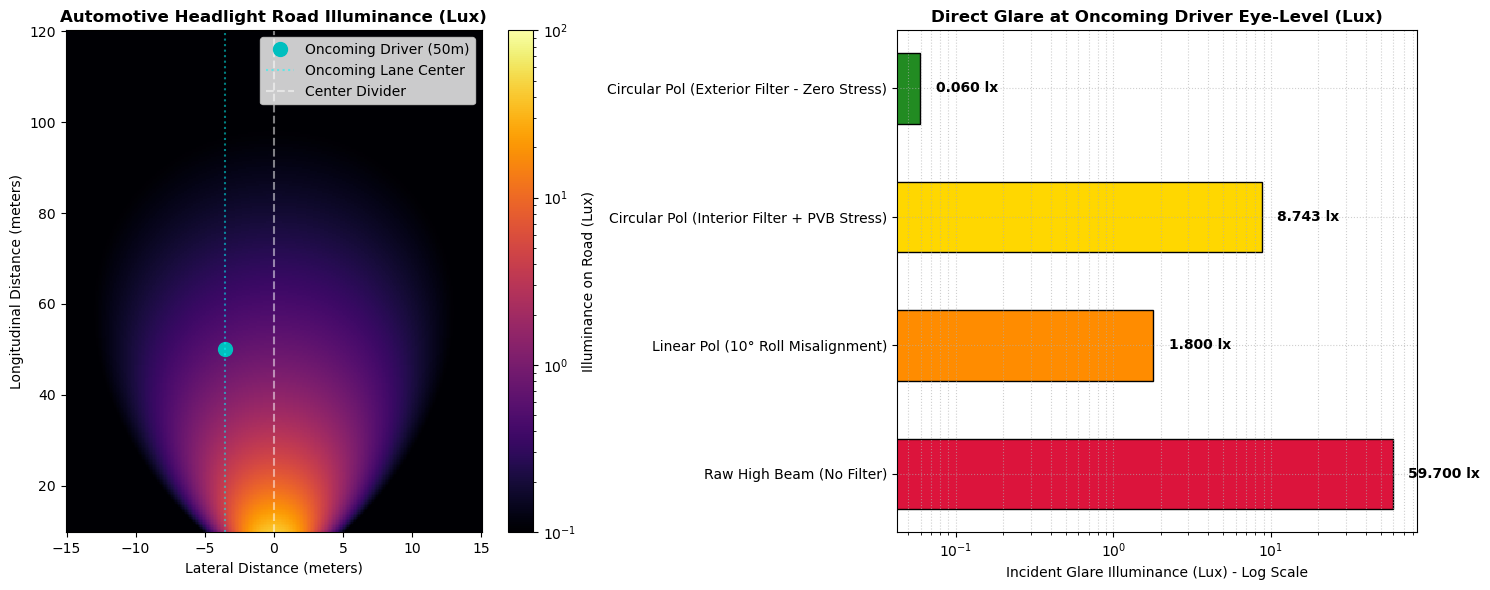

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# 1. Road Grid Coordinates (meters)
# x: lateral distance (-15m oncoming lane to +15m roadside)
# z: longitudinal distance down the road (10m to 120m ahead)
x = np.linspace(-15, 15, 300)
z = np.linspace(10, 120, 300)
X, Z = np.meshgrid(x, z)

# Oncoming driver position: lane center x = -3.5m, eye height y = 1.2m
oncoming_x = -3.5
oncoming_z = 50.0  # oncoming car located 50m away

# 2. Geometric Headlight Beam Model (Asymmetric High Beam)
# Headlamp origin: (x_0, y_0, z_0)
lamp_left_x, lamp_right_x = 0.8, -0.8
lamp_height = 0.65  # 65 cm mounting height

def compute_beam_lux(lamp_x):
    dx = X - lamp_x
    dz = Z
    distance_sq = dx**2 + lamp_height**2 + dz**2
    angle_horiz = np.arctan2(dx, dz)
    angle_vert = np.arctan2(-lamp_height, dz)
    
    # Gaussian angular distribution (high beam core with lateral spread)
    intensity_cd = 75000 * np.exp(-(angle_horiz / 0.18)**2 - (angle_vert / 0.08)**2)
    # Cosine law of illuminance on road plane
    cos_theta = lamp_height / np.sqrt(distance_sq)
    lux = (intensity_cd / distance_sq) * cos_theta
    return lux

total_road_lux = compute_beam_lux(lamp_left_x) + compute_beam_lux(lamp_right_x)

# 3. Polarization Extinction Calculation at Oncoming Driver Eye-Level
# Target: Illuminance entering oncoming driver's eye (direct line-of-sight ray)
r_eye_sq = (oncoming_x)**2 + (1.2 - lamp_height)**2 + oncoming_z**2
E_raw_eye = (75000 * 2 / r_eye_sq)  # Direct incident lux without filtering

# Extinction scenarios:
transmission_no_filter = 1.00
# Linear filter with 10 deg bank/roll misalignment: cos^2(90 - 10) = sin^2(10 deg)
transmission_linear_tilt = np.sin(np.radians(10))**2  
# Circular filter with exterior mount (ideal extinction)
transmission_circular_exterior = 0.001  
# Circular filter with interior mount (windshield PVB stress retardation delta = 0.25 pi)
delta_windshield = 0.25 * np.pi
transmission_circular_interior = np.sin(delta_windshield / 2)**2

scenarios = [
    ("Raw High Beam (No Filter)", transmission_no_filter),
    ("Linear Pol (10° Roll Misalignment)", transmission_linear_tilt),
    ("Circular Pol (Interior Filter + PVB Stress)", transmission_circular_interior),
    ("Circular Pol (Exterior Filter - Zero Stress)", transmission_circular_exterior)
]

glare_lux_values = [E_raw_eye * t for _, t in scenarios]
labels = [s[0] for s in scenarios]

# 4. Visualization: Road Beam Heatmap + Driver Glare Bar Chart
fig = plt.figure(figsize=(15, 6))

# Subplot 1: Spatial Road Illuminance (Bird's-Eye View)
ax1 = fig.add_subplot(1, 2, 1)
c = ax1.pcolormesh(X, Z, total_road_lux, cmap='inferno', norm=LogNorm(vmin=0.1, vmax=100), shading='auto')
ax1.plot(oncoming_x, oncoming_z, 'co', markersize=10, label='Oncoming Driver (50m)')
ax1.axvline(-3.5, color='cyan', linestyle=':', alpha=0.5, label='Oncoming Lane Center')
ax1.axvline(0, color='white', linestyle='--', alpha=0.5, label='Center Divider')
ax1.set_title("Automotive Headlight Road Illuminance (Lux)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Lateral Distance (meters)", fontsize=10)
ax1.set_ylabel("Longitudinal Distance (meters)", fontsize=10)
ax1.legend(loc='upper right')
cb = fig.colorbar(c, ax=ax1)
cb.set_label("Illuminance on Road (Lux)", fontsize=10)

# Subplot 2: Glare Intensity Reaching Oncoming Driver's Eye
ax2 = fig.add_subplot(1, 2, 2)
colors = ['crimson', 'darkorange', 'gold', 'forestgreen']
bars = ax2.barh(labels, glare_lux_values, color=colors, edgecolor='black', height=0.55)
ax2.set_xscale('log')
ax2.set_title("Direct Glare at Oncoming Driver Eye-Level (Lux)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Incident Glare Illuminance (Lux) - Log Scale", fontsize=10)
ax2.grid(True, which='both', linestyle=':', alpha=0.6)

# Add numeric annotations to bars
for bar in bars:
    w = bar.get_width()
    ax2.text(w * 1.25, bar.get_y() + bar.get_height() / 2, f"{w:.3f} lx", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

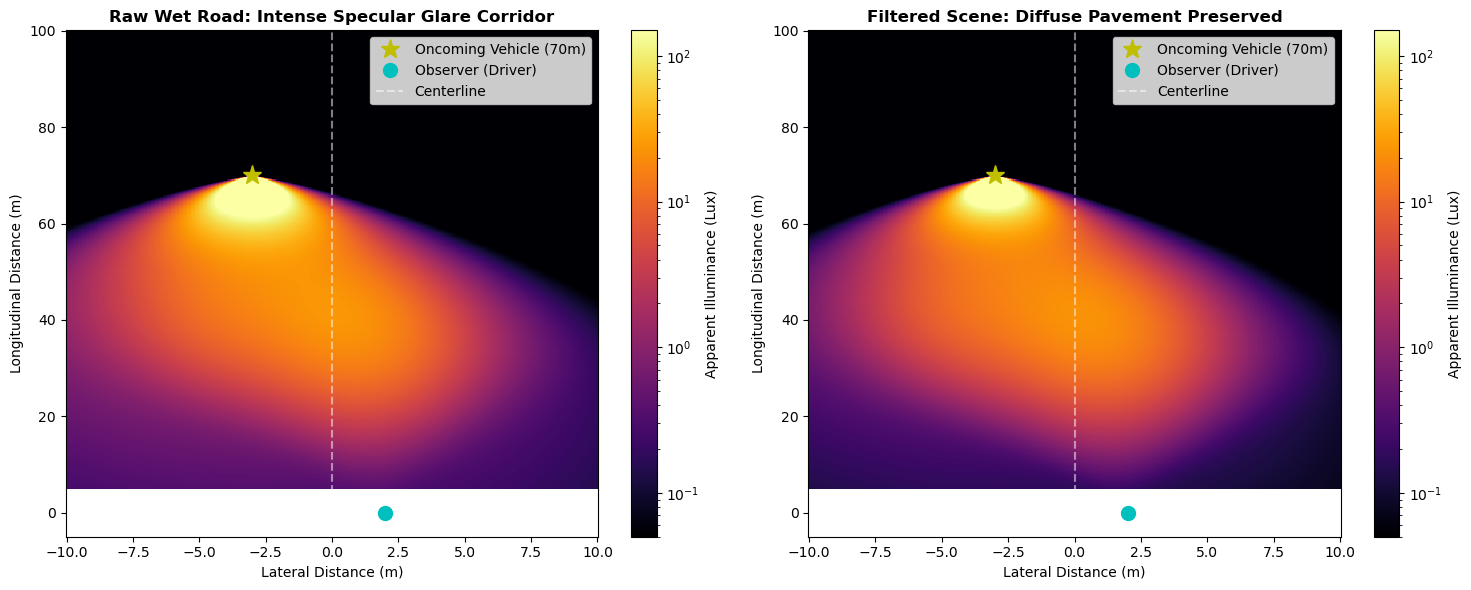

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# 1. 2D Road Grid (Meters)
# x: lateral road coordinates (-10m oncoming lane to +10m shoulder)
# z: longitudinal distance down the road (5m to 100m)
x = np.linspace(-10, 10, 400)
z = np.linspace(5, 100, 400)
X, Z = np.meshgrid(x, z)

# Observer (Driver) position: lane center x = 2.0m, eye height y = 1.2m at z = 0m
obs_x, obs_y, obs_z = 2.0, 1.2, 0.0

# Oncoming Car position: oncoming lane center x = -3.0m, z = 70.0m
source_x, source_z = -3.0, 70.0
source_h = 0.65  # headlight height
source_intensity_cd = 75000  # Candela per headlamp

# 2. Diffuse Road Illumination (Dry Baseline)
dx = X - source_x
dz = Z - source_z
dist_sq = dx**2 + source_h**2 + dz**2
cos_inc = source_h / np.sqrt(dist_sq)
# Headlight angular distribution (pointing forward along -z direction)
angle_headlight = np.arctan2(dx, -dz)
lamp_pattern = np.exp(-(angle_headlight / 0.22)**2)
diffuse_road_lux = (2 * source_intensity_cd * lamp_pattern / dist_sq) * cos_inc

# 3. Wet Road Specular Reflection Glare (Fresnel Reflection)
# Define wet zone / puddles between z=20m and z=60m, across both lanes
wetness = np.exp(-((Z - 42) / 16)**2) * (0.8 + 0.2 * np.sin(0.6 * X))

# Vector from source to road point (X, 0, Z)
r_in_x = X - source_x
r_in_y = -source_h
r_in_z = Z - source_z
r_in_mag = np.sqrt(r_in_x**2 + r_in_y**2 + r_in_z**2)

# Vector from road point (X, 0, Z) to observer eye (obs_x, obs_y, obs_z)
r_out_x = obs_x - X
r_out_y = obs_y
r_out_z = obs_z - Z
r_out_mag = np.sqrt(r_out_x**2 + r_out_y**2 + r_out_z**2)

# Specular half-vector deviation (Phong-like specular reflection)
# Ideal specular mirror ray reflected off road plane (y=0):
refl_x = r_in_x
refl_y = -r_in_y  # flips upward (+y)
refl_z = r_in_z
refl_mag = r_in_mag

# Dot product between reflected ray and vector to observer's eye
cos_spec = (refl_x * r_out_x + refl_y * r_out_y + refl_z * r_out_z) / (refl_mag * r_out_mag)
cos_spec = np.clip(cos_spec, 0.0, 1.0)

# Specular reflection sharpness (rough wet asphalt specular exponent ~ 35)
specular_exponent = 35
# Fresnel reflectance of water (R ~ 0.02 at normal, reaching 0.40+ at grazing angles)
theta_inc = np.arccos(source_h / r_in_mag)
fresnel_R = 0.02 + 0.98 * (1.0 - np.cos(theta_inc))**5

specular_glare_lux = (2 * source_intensity_cd * fresnel_R / (r_in_mag + r_out_mag)**2) * (cos_spec**specular_exponent) * wetness

# Total unpolarized road luminance / apparent brightness
unpolarized_total = diffuse_road_lux + specular_glare_lux

# 4. Polarization Filtering Effects
# Specular reflection flips RCP -> LCP.
# Diffuse reflection depolarizes light (50% unpolarized).
# Analyzer designed to block direct RCP:
# - Transmits LCP (specular road glare passes through unless an auxiliary LP stage is used)
# - Transmits 50% of diffuse depolarized pavement
# Exterior mount extinction of oncoming direct beam = 99.9%
polarized_diffuse = 0.50 * diffuse_road_lux
# Single bounce flips RCP to LCP:
polarized_specular_leakage = specular_glare_lux * 1.0  # LCP passes through an RCP-extinction analyzer

filtered_total = polarized_diffuse + polarized_specular_leakage

# 5. Visualizing the Road Maps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Map 1: Raw Wet Road (Direct + Specular Glare)
c1 = ax1.pcolormesh(X, Z, unpolarized_total, cmap='inferno', norm=LogNorm(vmin=0.05, vmax=150), shading='auto')
ax1.plot(source_x, source_z, 'y*', markersize=14, label='Oncoming Vehicle (70m)')
ax1.plot(obs_x, obs_z, 'co', markersize=10, label='Observer (Driver)')
ax1.axvline(0, color='white', linestyle='--', alpha=0.5, label='Centerline')
ax1.set_title("Raw Wet Road: Intense Specular Glare Corridor", fontsize=12, fontweight='bold')
ax1.set_xlabel("Lateral Distance (m)", fontsize=10)
ax1.set_ylabel("Longitudinal Distance (m)", fontsize=10)
ax1.legend(loc='upper right')
cb1 = fig.colorbar(c1, ax=ax1)
cb1.set_label("Apparent Illuminance (Lux)", fontsize=10)

# Map 2: Filtered Road Surface
c2 = ax2.pcolormesh(X, Z, filtered_total, cmap='inferno', norm=LogNorm(vmin=0.05, vmax=150), shading='auto')
ax2.plot(source_x, source_z, 'y*', markersize=14, label='Oncoming Vehicle (70m)')
ax2.plot(obs_x, obs_z, 'co', markersize=10, label='Observer (Driver)')
ax2.axvline(0, color='white', linestyle='--', alpha=0.5, label='Centerline')
ax2.set_title("Filtered Scene: Diffuse Pavement Preserved", fontsize=12, fontweight='bold')
ax2.set_xlabel("Lateral Distance (m)", fontsize=10)
ax2.set_ylabel("Longitudinal Distance (m)", fontsize=10)
ax2.legend(loc='upper right')
cb2 = fig.colorbar(c2, ax=ax2)
cb2.set_label("Apparent Illuminance (Lux)", fontsize=10)

plt.tight_layout()
plt.show()

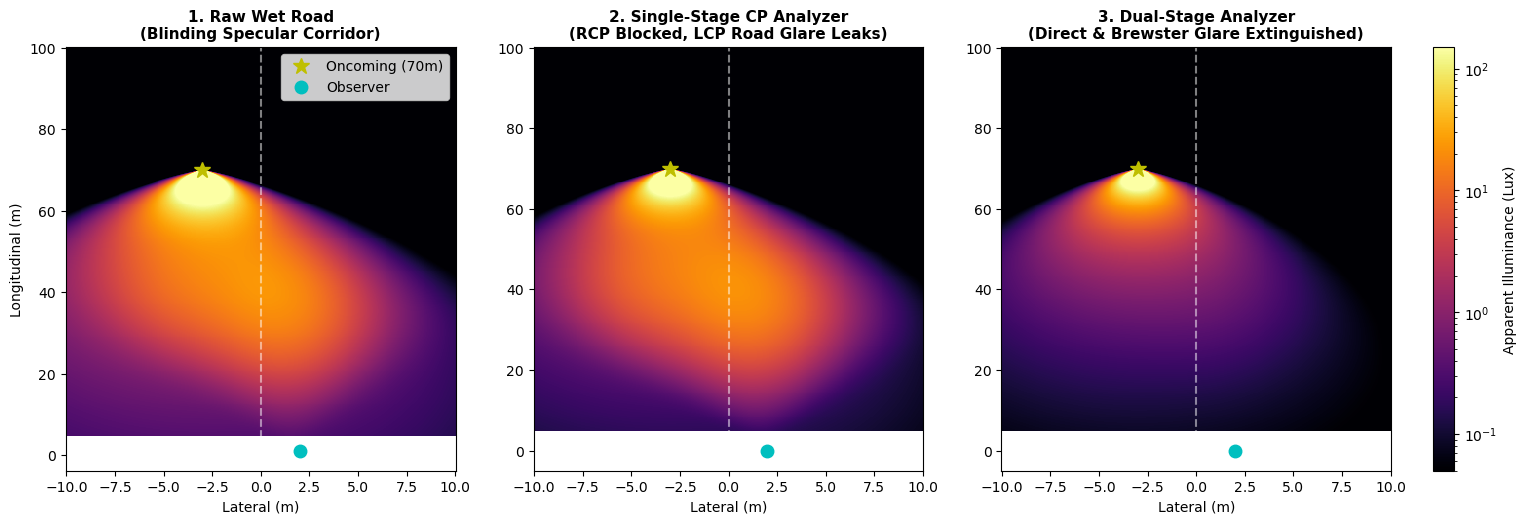

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# 1. 2D Road Grid (Meters)
x = np.linspace(-10, 10, 400)
z = np.linspace(5, 100, 400)
X, Z = np.meshgrid(x, z)

# Observer: lane center x = 2.0m, eye height y = 1.2m at z = 0m
obs_x, obs_y, obs_z = 2.0, 1.2, 0.0

# Oncoming Car: oncoming lane x = -3.0m, z = 70.0m
source_x, source_z = -3.0, 70.0
source_h = 0.65
source_intensity_cd = 75000

# 2. Geometry & Diffuse Illumination
dx = X - source_x
dz = Z - source_z
dist_sq = dx**2 + source_h**2 + dz**2
cos_inc = source_h / np.sqrt(dist_sq)
angle_headlight = np.arctan2(dx, -dz)
lamp_pattern = np.exp(-(angle_headlight / 0.22)**2)
diffuse_road_lux = (2 * source_intensity_cd * lamp_pattern / dist_sq) * cos_inc

# 3. Wet Road Specular Glare (Fresnel / Brewster Reflection)
wetness = np.exp(-((Z - 42) / 16)**2) * (0.8 + 0.2 * np.sin(0.6 * X))

r_in_mag = np.sqrt(dx**2 + (-source_h)**2 + dz**2)
r_out_x = obs_x - X
r_out_y = obs_y
r_out_z = obs_z - Z
r_out_mag = np.sqrt(r_out_x**2 + r_out_y**2 + r_out_z**2)

# Specular reflection vector
cos_spec = (dx * r_out_x + source_h * r_out_y + dz * r_out_z) / (r_in_mag * r_out_mag)
cos_spec = np.clip(cos_spec, 0.0, 1.0)

# Grazing angle Fresnel reflectance (R_s dominates near Brewster/grazing)
theta_inc = np.arccos(source_h / r_in_mag)
fresnel_Rs = 0.02 + 0.98 * (1.0 - np.cos(theta_inc))**5
specular_exponent = 35
specular_glare_lux = (2 * source_intensity_cd * fresnel_Rs / (r_in_mag + r_out_mag)**2) * (cos_spec**specular_exponent) * wetness

# Baseline Unpolarized Field
raw_unpolarized = diffuse_road_lux + specular_glare_lux

# 4. Filter Pipeline Stages

# Case A: Single-Stage CP Analyzer (Extinguishes RCP)
# - Diffuse pavement depolarized: 50% transmission
# - Specular bounce flips RCP -> LCP: Transmitted at ~100% through RCP-analyzer
single_stage_diffuse = 0.50 * diffuse_road_lux
single_stage_specular = specular_glare_lux * 1.0
single_stage_total = single_stage_diffuse + single_stage_specular

# Case B: Dual-Stage Analyzer (CP Extinction + Vertical Linear Polarizer)
# - Stage 1 resolves RCP direct oncoming beam.
# - Stage 2 (Vertical LP) eliminates horizontally polarized Brewster glare:
#   Brewster reflections are s-polarized (horizontal). Transmission through vertical LP: cos^2(90°) ~ 0.005.
# - Diffuse pavement transmits ~25% total intensity (50% stage 1 * 50% stage 2).
dual_stage_diffuse = 0.25 * diffuse_road_lux
dual_stage_specular = specular_glare_lux * 0.005  # 99.5% extinction of Brewster glare
dual_stage_total = dual_stage_diffuse + dual_stage_specular

# 5. Visualization: Three-Stage Comparison

# Using layout='constrained' prevents colorbar collisions across subplots
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5))

norm_scale = LogNorm(vmin=0.05, vmax=150)

# Plot 1: Raw Wet Road
c1 = ax1.pcolormesh(X, Z, raw_unpolarized, cmap='inferno', norm=norm_scale, shading='auto')
ax1.plot(source_x, source_z, 'y*', markersize=12, label='Oncoming (70m)')
ax1.plot(obs_x, obs_y, 'co', markersize=9, label='Observer')
ax1.axvline(0, color='white', linestyle='--', alpha=0.5)
ax1.set_title("1. Raw Wet Road\n(Blinding Specular Corridor)", fontsize=11, fontweight='bold')
ax1.set_xlabel("Lateral (m)")
ax1.set_ylabel("Longitudinal (m)")
ax1.legend(loc='upper right')

# Plot 2: Single-Stage CP Analyzer
c2 = ax2.pcolormesh(X, Z, single_stage_total, cmap='inferno', norm=norm_scale, shading='auto')
ax2.plot(source_x, source_z, 'y*', markersize=12)
ax2.plot(obs_x, obs_z, 'co', markersize=9)
ax2.axvline(0, color='white', linestyle='--', alpha=0.5)
ax2.set_title("2. Single-Stage CP Analyzer\n(RCP Blocked, LCP Road Glare Leaks)", fontsize=11, fontweight='bold')
ax2.set_xlabel("Lateral (m)")

# Plot 3: Dual-Stage Analyzer
c3 = ax3.pcolormesh(X, Z, dual_stage_total, cmap='inferno', norm=norm_scale, shading='auto')
ax3.plot(source_x, source_z, 'y*', markersize=12)
ax3.plot(obs_x, obs_z, 'co', markersize=9)
ax3.axvline(0, color='white', linestyle='--', alpha=0.5)
ax3.set_title("3. Dual-Stage Analyzer\n(Direct & Brewster Glare Extinguished)", fontsize=11, fontweight='bold')
ax3.set_xlabel("Lateral (m)")

# Fixed Colorbar Placement:
# 1. We attach to all three subplots [ax1, ax2, ax3]
# 2. 'fraction' controls its width, 'pad' creates a safety margin outside ax3
cb = fig.colorbar(c3, ax=[ax1, ax2, ax3], orientation='vertical', fraction=0.02, pad=0.03)
cb.set_label("Apparent Illuminance (Lux)", fontsize=10)

# (Note: Do NOT call plt.tight_layout() here, layout='constrained' handles spacing automatically)
plt.show()

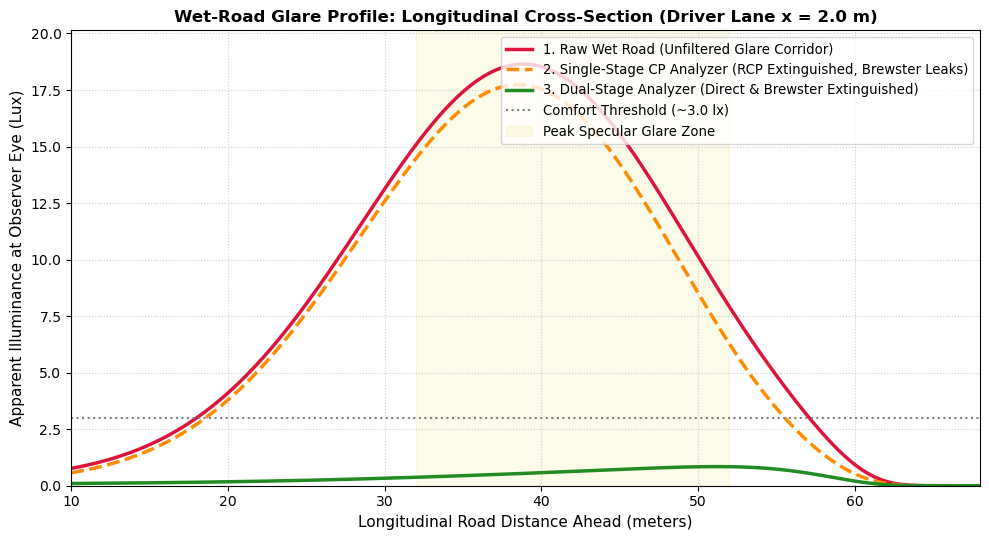

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Longitudinal Cross-Section (Driver's Lane: x = 2.0m)
obs_x = 2.0
obs_y = 1.2
obs_z = 0.0

source_x = -3.0
source_z = 70.0
source_h = 0.65
source_intensity_cd = 75000

# Evaluation line along road distance z
z_eval = np.linspace(10, 68, 500)
x_eval = np.full_like(z_eval, obs_x)

# 2. Diffuse Road Illumination
dx = x_eval - source_x
dz = z_eval - source_z
dist_sq = dx**2 + source_h**2 + dz**2
cos_inc = source_h / np.sqrt(dist_sq)
angle_headlight = np.arctan2(dx, -dz)
lamp_pattern = np.exp(-(angle_headlight / 0.22)**2)
diffuse_road_lux = (2 * source_intensity_cd * lamp_pattern / dist_sq) * cos_inc

# 3. Specular Reflection (Brewster / Wet Road)
wetness = np.exp(-((z_eval - 42) / 16)**2)

r_in_mag = np.sqrt(dx**2 + (-source_h)**2 + dz**2)
r_out_x = obs_x - x_eval
r_out_y = obs_y
r_out_z = obs_z - z_eval
r_out_mag = np.sqrt(r_out_x**2 + r_out_y**2 + r_out_z**2)

cos_spec = (dx * r_out_x + source_h * r_out_y + dz * r_out_z) / (r_in_mag * r_out_mag)
cos_spec = np.clip(cos_spec, 0.0, 1.0)

theta_inc = np.arccos(source_h / r_in_mag)
fresnel_Rs = 0.02 + 0.98 * (1.0 - np.cos(theta_inc))**5
specular_glare_lux = (2 * source_intensity_cd * fresnel_Rs / (r_in_mag + r_out_mag)**2) * (cos_spec**35) * wetness

# 4. Filter Case Definitions
# Case 1: Raw Unpolarized Field
case1_raw = diffuse_road_lux + specular_glare_lux

# Case 2: Single-Stage CP Analyzer (Blocks direct RCP, but LCP road glare passes)
case2_single_stage = (0.50 * diffuse_road_lux) + (1.0 * specular_glare_lux)

# Case 3: Dual-Stage Analyzer (CP + Vertical Linear Polarizer to block Brewster glare)
case3_dual_stage = (0.25 * diffuse_road_lux) + (0.005 * specular_glare_lux)

# 5. Clean Line Plot
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(z_eval, case1_raw, color='crimson', lw=2.5, label='1. Raw Wet Road (Unfiltered Glare Corridor)')
ax.plot(z_eval, case2_single_stage, color='darkorange', lw=2.5, linestyle='--', label='2. Single-Stage CP Analyzer (RCP Extinguished, Brewster Leaks)')
ax.plot(z_eval, case3_dual_stage, color='forestgreen', lw=2.5, linestyle='-', label='3. Dual-Stage Analyzer (Direct & Brewster Extinguished)')

# Retinal Glare Discomfort Threshold reference
ax.axhline(3.0, color='gray', linestyle=':', lw=1.5, label='Comfort Threshold (~3.0 lx)')
ax.axvspan(32, 52, color='khaki', alpha=0.2, label='Peak Specular Glare Zone')

ax.set_title("Wet-Road Glare Profile: Longitudinal Cross-Section (Driver Lane x = 2.0 m)", fontsize=12, fontweight='bold')
ax.set_xlabel("Longitudinal Road Distance Ahead (meters)", fontsize=11)
ax.set_ylabel("Apparent Illuminance at Observer Eye (Lux)", fontsize=11)
ax.set_xlim(10, 68)
ax.set_ylim(0, max(case1_raw) * 1.08)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right', frameon=True, fontsize=9.5)

plt.tight_layout()
plt.show()

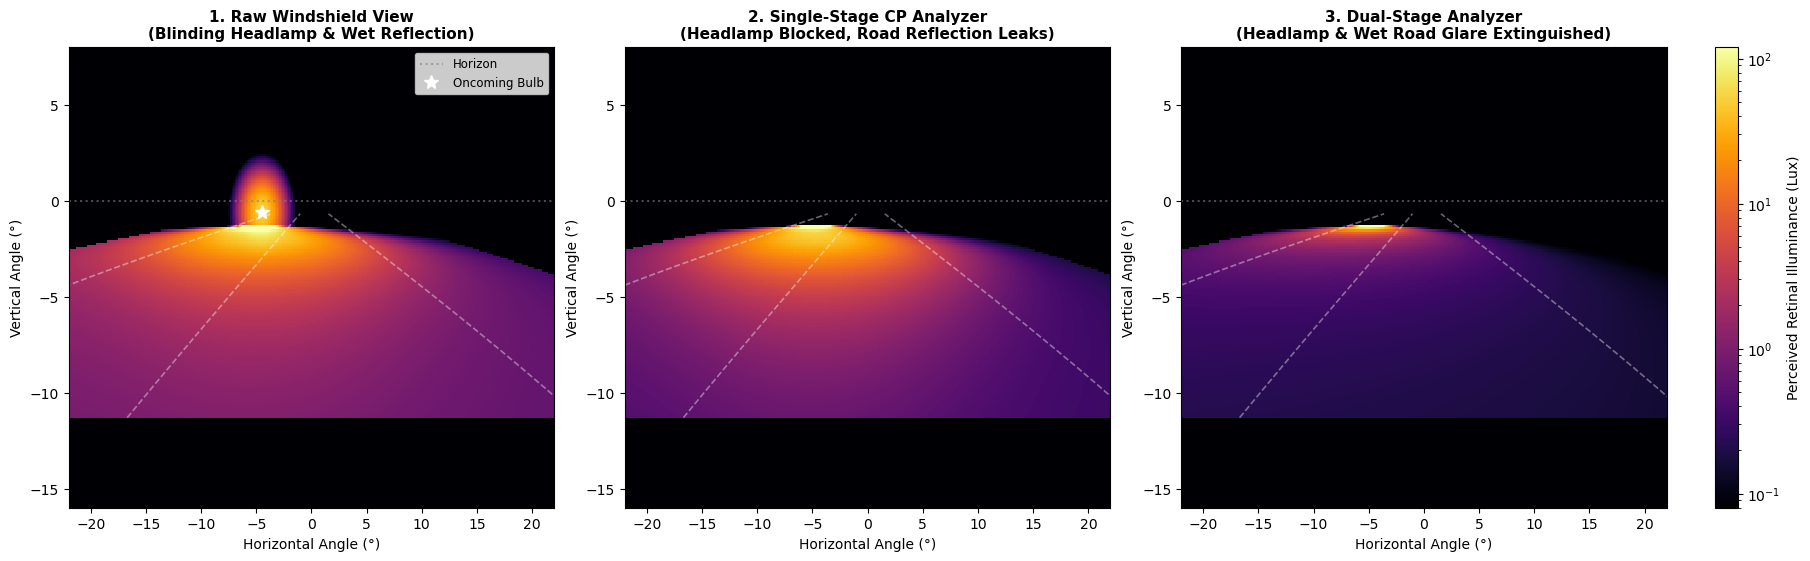

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# ==========================================
# 1. OBSERVER & GEOMETRY SPECIFICATION
# ==========================================
# Observer eye: vehicle lane center x = 1.8m, height y = 1.2m, longitudinal z = 0m
obs_x, obs_y, obs_z = 1.8, 1.2, 0.0

# Oncoming Car: oncoming lane center x = -2.5m, longitudinal z = 55.0m
source_x, source_z = -2.5, 55.0
source_h = 0.65       # Headlight height (m)
source_intensity = 80000  # Candela per headlamp

# Camera Angular Field of View (Windshield View)
# az: horizontal visual angle (-25° to +25°)
# el: vertical visual angle (-18° road to +12° sky/horizon)
az_deg = np.linspace(-25, 25, 360)
el_deg = np.linspace(-18, 12, 260)
AZ, EL = np.meshgrid(np.radians(az_deg), np.radians(el_deg))

# ==========================================
# 2. INVERSE PERSPECTIVE RAY TRACING TO ROAD
# ==========================================
# For pixels looking down at the road (EL < 0):
# Road sits at Y = 0 => (0 - obs_y) / Z = tan(EL) => Z = -obs_y / tan(EL)
Z_road = np.where(EL < -1e-3, -obs_y / np.tan(EL), np.nan)
X_road = np.where(EL < -1e-3, obs_x + Z_road * np.tan(AZ), np.nan)

# Valid road zone (longitudinal 6m to 100m)
valid_road = (Z_road >= 6.0) & (Z_road <= 100.0) & (np.abs(X_road) <= 9.0)

# Distance and incidence calculations
dx = np.where(valid_road, X_road - source_x, np.nan)
dz = np.where(valid_road, Z_road - source_z, np.nan)
dist_headlight_sq = dx**2 + source_h**2 + dz**2
cos_inc = source_h / np.sqrt(dist_headlight_sq)

# Headlight beam spread pointing towards observer
beam_spread = np.exp(-((np.arctan2(dx, -dz)) / 0.24)**2)
diffuse_road_lux = np.where(valid_road, (2 * source_intensity * beam_spread / dist_headlight_sq) * cos_inc, 0.0)

# ==========================================
# 3. WET ROAD SPECULAR GLOSS (BREWSTER)
# ==========================================
r_in_mag = np.sqrt(dx**2 + (-source_h)**2 + dz**2)
r_out_x = obs_x - X_road
r_out_y = obs_y
r_out_z = -Z_road
r_out_mag = np.sqrt(r_out_x**2 + r_out_y**2 + r_out_z**2)

# Specular half-vector alignment
cos_spec = (dx * r_out_x + source_h * r_out_y + dz * r_out_z) / (r_in_mag * r_out_mag)
cos_spec = np.clip(np.where(valid_road, cos_spec, 0.0), 0.0, 1.0)

theta_inc = np.arccos(np.clip(source_h / r_in_mag, 0.0, 1.0))
fresnel_Rs = 0.02 + 0.98 * (1.0 - np.cos(theta_inc))**5
wet_zone = np.exp(-((Z_road - 38) / 15)**2)

specular_road_lux = np.where(valid_road, 
    (2 * source_intensity * fresnel_Rs / (r_in_mag + r_out_mag)**2) * (cos_spec**32) * wet_zone, 0.0)

# ==========================================
# 4. DIRECT HEADLIGHT GLARE IN WINDSHIELD
# ==========================================
# Angular position of oncoming headlamp bulb in observer FOV
az_bulb = np.arctan2(source_x - obs_x, source_z)
el_bulb = np.arctan2(source_h - obs_y, source_z)

# Retinal/bloom spread around direct headlamp source
ang_dist_sq = (AZ - az_bulb)**2 + (EL - el_bulb)**2
direct_glare_lux = (2 * source_intensity / (source_z**2)) * np.exp(-ang_dist_sq / (np.radians(1.2))**2)

# ==========================================
# 5. FILTER SCENARIOS
# ==========================================
# Case 1: Raw Unfiltered (Direct beam + wet road specular)
pov_raw = diffuse_road_lux + specular_road_lux + direct_glare_lux

# Case 2: Single-Stage CP Analyzer (Blocks direct RCP, but Brewster LCP leaks)
pov_single_stage = (0.50 * diffuse_road_lux) + (1.0 * specular_road_lux) + (0.001 * direct_glare_lux)

# Case 3: Dual-Stage Analyzer (Direct & Brewster Glare Extinguished)
pov_dual_stage = (0.25 * diffuse_road_lux) + (0.005 * specular_road_lux) + (0.001 * direct_glare_lux)

# ==========================================
# 6. VISUALIZATION (DRIVER POV)
# ==========================================
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5.5), layout='constrained')
norm_scale = LogNorm(vmin=0.08, vmax=120)

def style_windshield_view(ax, data, title):
    im = ax.pcolormesh(az_deg, el_deg, data, cmap='inferno', norm=norm_scale, shading='auto')
    # Horizon line
    ax.axhline(0, color='gray', linestyle=':', alpha=0.6, label='Horizon')
    # Perspective lane lines (Road edges and center)
    z_line = np.linspace(6, 100, 100)
    for lane_x in [-4.5, 0.0, 4.5]:
        line_az = np.degrees(np.arctan2(lane_x - obs_x, z_line))
        line_el = np.degrees(np.arctan2(0.0 - obs_y, z_line))
        ax.plot(line_az, line_el, color='white', linestyle='--', alpha=0.4, lw=1.2)
    
    ax.set_xlim(-22, 22)
    ax.set_ylim(-16, 8)
    ax.set_xlabel("Horizontal Angle (°)", fontsize=10)
    ax.set_ylabel("Vertical Angle (°)", fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold')
    return im

style_windshield_view(ax1, pov_raw, "1. Raw Windshield View\n(Blinding Headlamp & Wet Reflection)")
style_windshield_view(ax2, pov_single_stage, "2. Single-Stage CP Analyzer\n(Headlamp Blocked, Road Reflection Leaks)")
im3 = style_windshield_view(ax3, pov_dual_stage, "3. Dual-Stage Analyzer\n(Headlamp & Wet Road Glare Extinguished)")

ax1.plot(np.degrees(az_bulb), np.degrees(el_bulb), 'w*', markersize=10, label='Oncoming Bulb')
ax1.legend(loc='upper right', fontsize=8.5)

cb = fig.colorbar(im3, ax=[ax1, ax2, ax3], orientation='vertical', fraction=0.02, pad=0.03)
cb.set_label("Perceived Retinal Illuminance (Lux)", fontsize=10)

plt.show()